In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Monai_ACDC-Project-work"
)

CHECKPOINT = PROJECT_DIR / "checkpoints" / "best_model.pt"

print("Project exists:", PROJECT_DIR.exists())
print("Checkpoint exists:", CHECKPOINT.exists())
print("Checkpoint path:", CHECKPOINT)

Project exists: True
Checkpoint exists: True
Checkpoint path: /content/drive/MyDrive/Monai_ACDC-Project-work/checkpoints/best_model.pt


In [7]:
!pip install -q monai nibabel numpy scipy matplotlib torch streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 88.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 90.3 MB/s eta 0:00:00


In [8]:
%cd /content/drive/MyDrive/Monai_ACDC-Project-work

!python testing.py --split val

/content/drive/MyDrive/Monai_ACDC-Project-work
I0000 00:00:1791886338.981646    1562 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791886341.244339    1562 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Failed to load nvtiff library! Please install nvTIFF (see https://docs.nvidia.com/cuda/nvtiff/userguide.html#installing-nvtiff).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvTIFF wheel: e.g. `python3 -m pip install nvidia-nvtiff-cu13`
[ERROR] [nvtiff_ext] Failed to load nvTIFF library or retrieve version. Decoders and encoders will not be registered.
Failed to load nvjpeg2k library! Please install nvJPEG2000 (see https://docs.nvidia.com/cuda/nvjpeg2000/userguide.html#installing-nvjpeg2

In [9]:
!python inference.py \
  --image "/content/drive/MyDrive/Monai_ACDC-Project-work/ACDC/training/patient001/patient001_frame01.nii.gz"

I0000 00:00:1791886455.232218    2142 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791886457.470803    2142 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Failed to load nvtiff library! Please install nvTIFF (see https://docs.nvidia.com/cuda/nvtiff/userguide.html#installing-nvtiff).
Note: If using nvImageCodec's Python distribution, it is enough to install the nvTIFF wheel: e.g. `python3 -m pip install nvidia-nvtiff-cu13`
[ERROR] [nvtiff_ext] Failed to load nvTIFF library or retrieve version. Decoders and encoders will not be registered.
Failed to load nvjpeg2k library! Please install nvJPEG2000 (see https://docs.nvidia.com/cuda/nvjpeg2000/userguide.html#installing-nvjpeg2000).
Note: If using nvImageCodec's Python dist

/content/drive/MyDrive/Monai_ACDC-Project-work


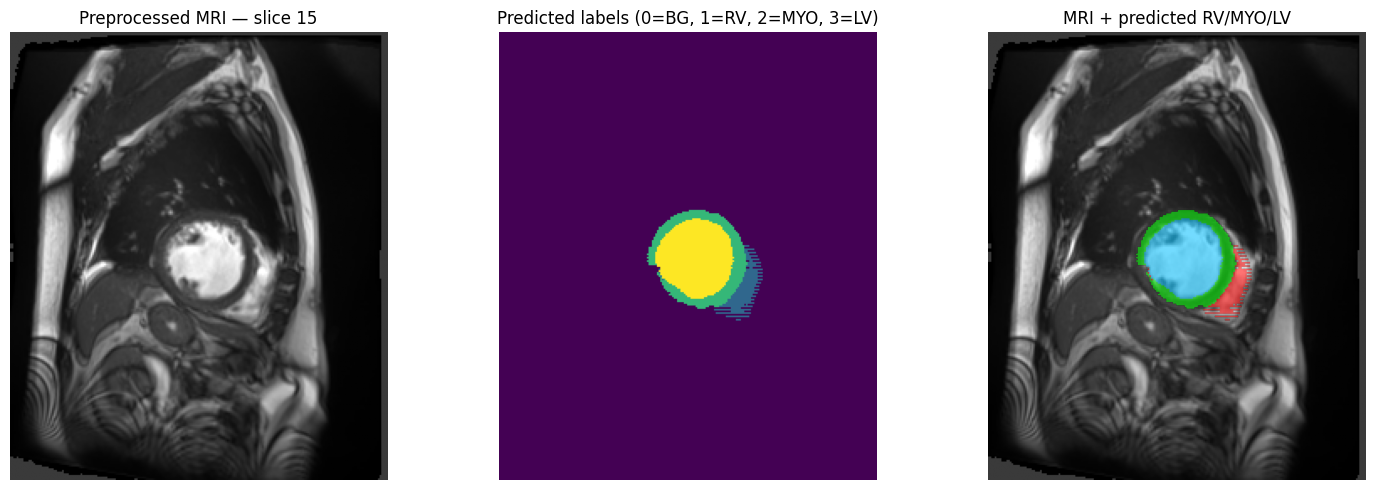

<Figure size 640x480 with 0 Axes>

In [10]:
%cd /content/drive/MyDrive/Monai_ACDC-Project-work

%run visualize_results.py --npz "outputs/patient001_frame01_prediction.npz"

# **Streamlit** application with pyngrok

In [11]:
!pip install -q -r requirements.txt

In [12]:
!pip install -q streamlit pyngrok

import subprocess
import time
from pathlib import Path
from pyngrok import ngrok

# 1. Project directory
PROJECT_DIR = "/content/drive/MyDrive/Monai_ACDC-Project-work"
%cd /content/drive/MyDrive/Monai_ACDC-Project-work

# 2. Enter your actual ngrok token
NGROK_AUTH_TOKEN = "3KaCaOW4uFXrmkJnhrxyR50pHMC_669Z1L5V64qJtrSAV1F5c"

ngrok.set_auth_token(NGROK_AUTH_TOKEN)

# 3. Close any existing ngrok tunnels
try:
    ngrok.kill()
except Exception:
    pass

# 4. Stop the previous Streamlit process on port 8501
subprocess.run(
    ["bash", "-lc", "fuser -k 8501/tcp"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

# 5. Start Streamlit in the background
log_path = "/tmp/streamlit.log"

with open(log_path, "w") as log_file:
    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        cwd=PROJECT_DIR,
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

# 6. Wait for the server to start
for _ in range(15):
    result = subprocess.run(
        ["bash", "-lc", "curl -s http://127.0.0.1:8501/_stcore/health"],
        capture_output=True,
        text=True
    )

    if result.returncode == 0 and "ok" in result.stdout.lower():
        break

    if process.poll() is not None:
        print(Path(log_path).read_text())
        raise RuntimeError("Streamlit stopped unexpectedly.")

    time.sleep(1)
else:
    print(Path(log_path).read_text())
    raise RuntimeError("Streamlit did not become ready.")

# 7. Create the public tunnel
public_url = ngrok.connect(8501, "http")

print("\n✅ Streamlit application is running!")
print("🌐 Open your app here:", public_url)

/content/drive/MyDrive/Monai_ACDC-Project-work

✅ Streamlit application is running!
🌐 Open your app here: NgrokTunnel: "https://backboned-judgingly-tuesday.ngrok-free.dev" -> "http://localhost:8501"
